In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [10]:
# Chargement des données
df = pd.read_csv("https://raw.githubusercontent.com/AlexyCatelle/titanic-data-cleaning/refs/heads/main/csv/train_clean.csv")


In [11]:
# séparation variables explicatives / cible 

# X = les variables explicatives (features) : toutes les colonnes SAUF "Survived"
X = df.drop(columns=["Survived"])

# y = la cible (target) : ce que l'on veut prédire
y = df["Survived"]

In [12]:
#découpage entraînement / test 

# On coupe les données en deux parties :
#   - train (75 %) : le modèle apprend dessus
#   - test  (25 %) : le modèle est évalué sur des données qu'il n'a JAMAIS vues
# test_size=0.25    -> 25 % des lignes vont dans le jeu de test
# random_state=42   -> graine aléatoire fixe : le découpage est identique à chaque exécution (reproductible)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [13]:
# création et entraînement du modèle

# Création d'un arbre de décision pour classifier (prédire une catégorie : survivant ou non)
# max_depth=3     -> l'arbre ne peut pas dépasser 3 niveaux de questions : on limite sa complexité
#                    pour éviter le surapprentissage (overfitting) et garder un arbre lisible
# random_state=42 -> résultat reproductible (l'arbre peut départager des égalités au hasard)

dtc = DecisionTreeClassifier(random_state=42, max_depth=3)

# Entraînement : l'arbre cherche, à partir de X_train et y_train
dtc.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [14]:
# évaluation du modèle 

# Prédictions du modèle sur le jeu de test (données jamais vues pendant l'entraînement)
y_pred = dtc.predict(X_test)

# Accuracy sur le test : proportion de prédictions correctes (bonnes prédictions / total)
accuracy = accuracy_score(y_test, y_pred)
print(f"Précision du modèle : {accuracy:.2%}")

# Accuracy sur le train : permet de comparer avec le test pour repérer un éventuel surapprentissage
print("Accuracy Train :", round(dtc.score(X_train, y_train)*100,2),"%")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

Précision du modèle : 79.82%
Accuracy Train : 84.83 %

Rapport de classification :
              precision    recall  f1-score   support

           0       0.86      0.81      0.84       141
           1       0.70      0.78      0.74        82

    accuracy                           0.80       223
   macro avg       0.78      0.79      0.79       223
weighted avg       0.80      0.80      0.80       223




- **precision** (précision): quand le modèle prédit qu'une personne survit, il a raison dans 70 % des cas.

- **recall** (rappel / sensibilité): il retrouve 78 % des personnes qui ont réellement survécu.

- **f1-score** : représente l'équilibre entre la précision et le rappel.



Matrice de confusion : 


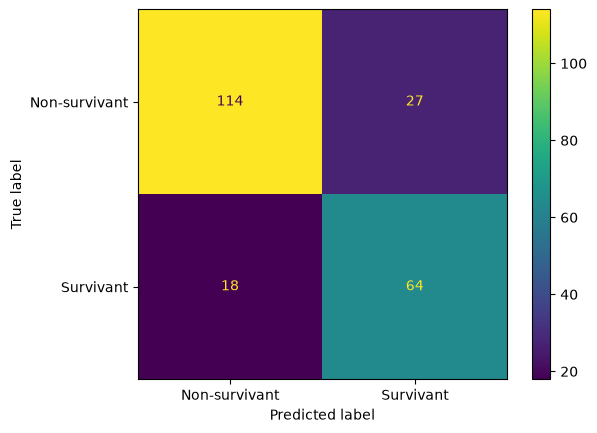

In [15]:
# matrice de confusion

print('Matrice de confusion : ')
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Non-survivant", "Survivant"]
)

plt.show()

### Signification de chaque case

- **Vrais négatifs (114)** : non-survivants correctement prédits comme non-survivants. Bonne prédiction.
- **Vrais positifs (64)** : survivants correctement prédits comme survivants. Bonne prédiction.
- **Faux positifs (27)** : le modèle a annoncé « survivant » alors que la personne n'a pas survécu. C'est une fausse alerte (erreur de type I).
- **Faux négatifs (18)** : le modèle a annoncé « non-survivant » alors que la personne a survécu. C'est un cas manqué (erreur de type II).

La **diagonale** (114 + 64 = 178) regroupe les bonnes prédictions ; en dehors de la diagonale (27 + 18 = 45), ce sont les erreurs. Total : 178 + 45 = 223 passagers.

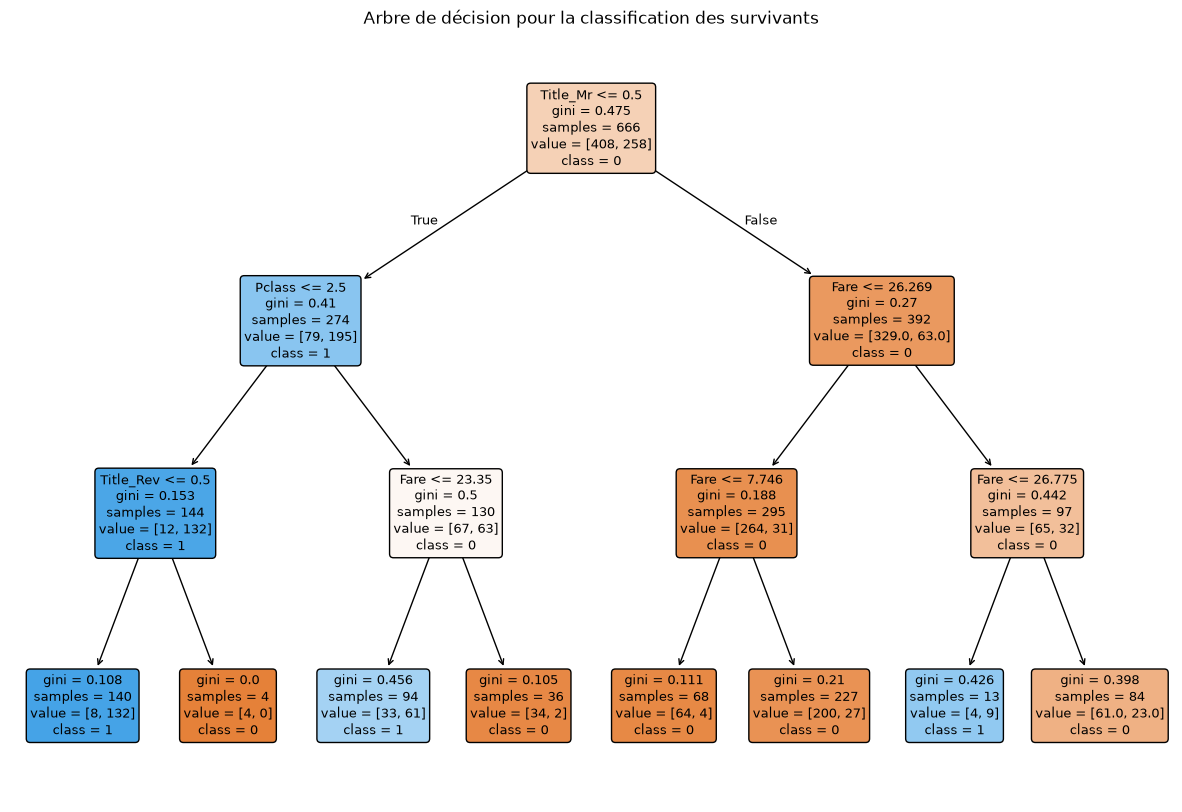

In [16]:
# Visualisation de l'arbre
plt.figure(figsize=(15, 10))
plot_tree(
    dtc,
    filled=True,
    feature_names=X.columns,
    class_names=[str(c) for c in dtc.classes_],
    rounded=True,
)
plt.title("Arbre de décision pour la classification des survivants")
plt.show()